# 08 KMeans 算法


本篇对应课程 `03_机器学习/08_KMeans算法`，根据 `02-笔记/KMeans聚类算法/聚类.md` 整理：先认识无监督聚类，再学习 KMeans 的分配与更新、聚类评估和客户分群。课程中的旧 API 与案例代码问题已在相应位置解释并修正。

资料：[机器学习课程网盘](https://pan.baidu.com/s/1NmWli9KoAeYtlpXTzhw-Jg?pwd=1234)，提取码 `1234`。

本篇的课程图、补充图均作为附件嵌入当前 Notebook。已读取教师 Markdown 和原始配图；`customers.csv` 已在代码目录确认存在，但下载没有成功，因此客户案例给出可复用流程，并用合成客户数据验证。离线实验与课程真实客户成绩分开说明，课堂视频未逐段转录。

沿用前几篇的阅读形式：全部为 Markdown 单元，代码放在 Python 代码块中；实践时可复制到代码单元运行。


## 学习路线

| 阶段 | 需要解决的问题 | 本篇重点 |
| --- | --- | --- |
| 聚类概念 | 没有标签，怎样发现结构？ | 相似性、簇、监督学习与无监督学习 |
| 算法原理 | 中心怎样从初始位置移动到合适位置？ | 最近中心分配、簇内均值更新、SSE |
| 动手实现 | 怎样调用和复现模型？ | KMeans API、n_init、标准化管道 |
| 评估与选 K | 分成几组更合适？ | SSE、轮廓系数、CH、稳定性 |
| 客户案例 | 怎样把簇变成业务理解？ | 去除 ID、类别编码、簇画像、原单位展示 |

前几篇的分类算法学习已知标签；本篇先从数据分组，再给分组解释。聚类得到的编号不是现成的业务标签。


## 1. 聚类：没有标签时寻找结构

聚类是典型的无监督学习：输入样本特征，根据选定的相似性把样本划分到不同簇。希望同簇样本更相似、不同簇更容易分开，但“相似”取决于特征、距离和业务问题。

| 对比项 | 监督分类 | 无监督聚类 |
| --- | --- | --- |
| 训练数据 | 特征与已知类别 | 样本特征 |
| 学习目标 | 学会预测已有标签 | 发现数据中的分组 |
| 输出含义 | 已定义的类别，如“流失/未流失” | 暂无天然语义的簇编号 |
| 评估依据 | 参考标签与预测标签 | 凝聚度、分离度、稳定性与业务效果 |

课程列出用户画像、内容分组、图像分割、异常探索等用途。聚类能帮助发现人群或可疑样本，但簇中心附近不一定都是优质客户，离中心远也不能直接证明异常。

常见聚类思路包括基于划分的 KMeans、基于层次的聚类、基于密度的 DBSCAN，以及基于概率分布的高斯混合。它们适合的簇形状和对噪声的处理不同。


## 2. 距离、质心与目标函数

KMeans 使用欧氏空间中的平方距离：

$$d(x_i,\mu_k)^2=\sum_{j=1}^{p}(x_{ij}-\mu_{kj})^2$$

距离与平方距离的最近中心相同，因为平方在非负数上保持大小顺序。均值向量是簇内点的平均位置，可以不与任何实际样本重合。

给定簇数 $K$，目标为最小化簇内误差平方和（SSE）：

$$J=\operatorname{SSE}=\sum_{k=1}^{K}\sum_{x_i\in C_k}\lVert x_i-\mu_k\rVert_2^2$$

$C_k$ 表示第 $k$ 个簇，$\mu_k$ 是它的质心。固定分组后，对一个簇的质心求导：

$$\frac{\partial}{\partial \mu_k}\sum_{x_i\in C_k}\lVert x_i-\mu_k\rVert^2=2\left(|C_k|\mu_k-\sum_{x_i\in C_k}x_i\right)=0$$

于是最优更新为：

$$\mu_k=\frac{1}{|C_k|}\sum_{x_i\in C_k}x_i$$

这就是名称中 **Means（均值）** 的来历。改成曼哈顿距离时，均值就不再是相应目标的最佳中心，不能随意替换距离却保留相同更新公式。


## 3. KMeans 的分配—更新过程

1. 设定 $K$，初始化 $K$ 个中心。
2. 固定中心，将每个样本分到最近的中心。
3. 固定分组，按簇内各特征的均值更新中心。
4. 重复分配和更新，直到收敛或达到迭代上限。

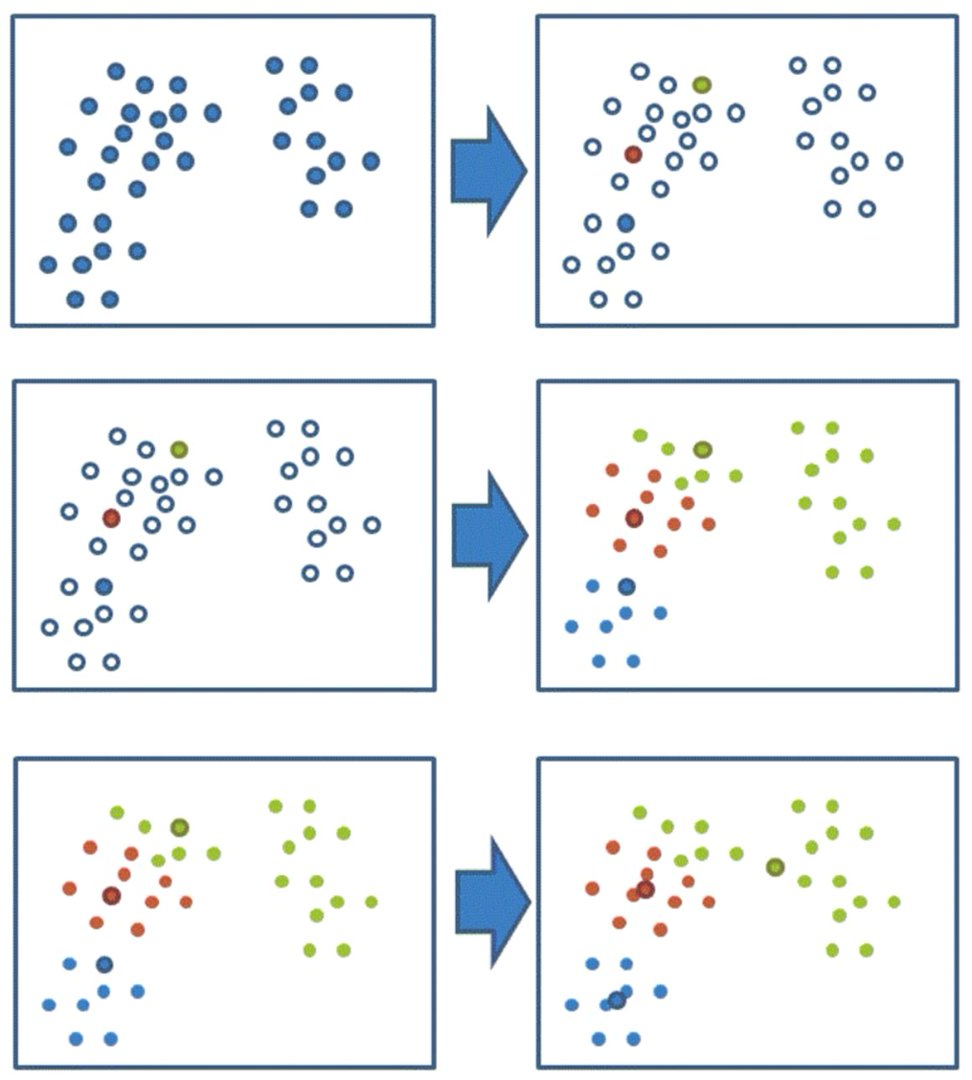

*课程图展示了中心初始化、颜色分配、中心移动和重新分组。*

在精确分配、非空簇均值更新等条件下，这两步都不会增大 SSE。它们通常收敛到某个局部解，不能保证全局最优。实际计算还要处理浮点误差、空簇和并列距离，不能只判断两个浮点中心“完全一样”。

常见停止条件是标签不再变化、中心变化达到容差，或者达到 `max_iter`。sklearn 的 `tol` 是针对中心变化的相对收敛容差，`n_iter_` 记录实际迭代次数。


### 3.1 分配与更新的补充示意

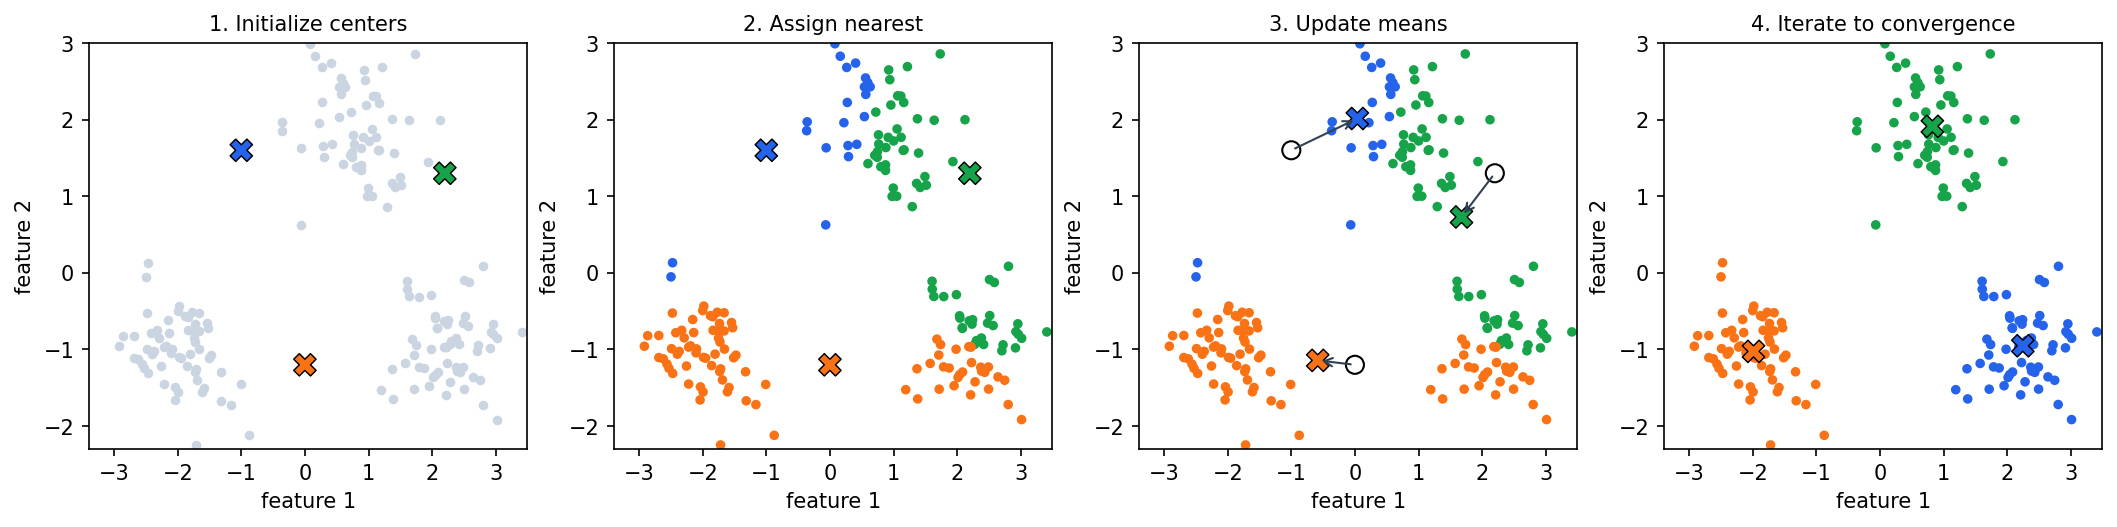

这是补充合成数据图。叉号是中心，更新图中的箭头是中心移动方向。分组随中心变化可能改变；不能把某一轮的颜色永久当作标签。

```text
初始化 K 个中心
重复：
    按最近中心分配所有样本
    对每个非空簇求均值，更新中心
    检查标签、中心变化和迭代上限
直到停止
```


## 4. 课程十五点手算：检查中心是否算对

课程以 $P_1=(7,7)$、$P_2=(2,3)$ 为初始中心，设 $K=2$。所有点如下：

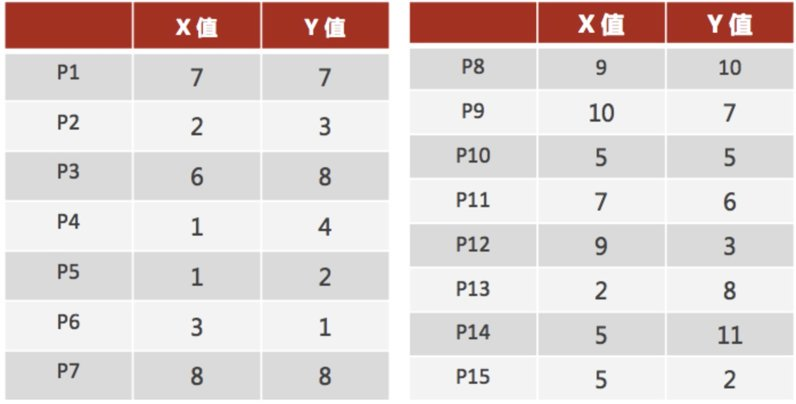

第一轮分配结果为：

- 簇 1：$P_1,P_3,P_7,P_8,P_9,P_{10},P_{11},P_{12},P_{14}$，共 9 点；
- 簇 2：$P_2,P_4,P_5,P_6,P_{13},P_{15}$，共 6 点。

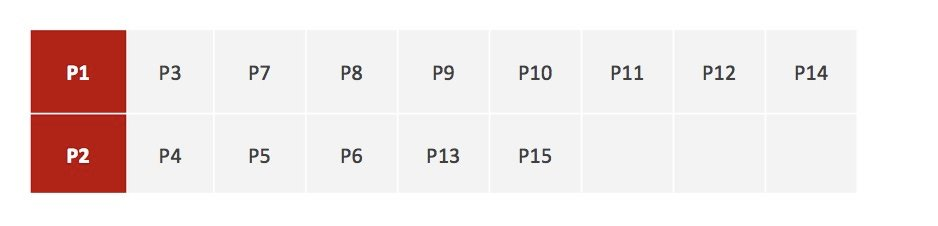

例如 $P_{10}=(5,5)$ 到两中心的平方距离分别为 $8$ 和 $13$，所以归入簇 1；$P_{13}=(2,8)$ 的平方距离分别为 $26$ 和 $25$，第一轮归入簇 2。

更新后：

$$\mu_1=\left(\frac{66}{9},\frac{65}{9}\right)\approx(7.3333,7.2222)$$

$$\mu_2=\left(\frac{14}{6},\frac{20}{6}\right)\approx(2.3333,3.3333)$$

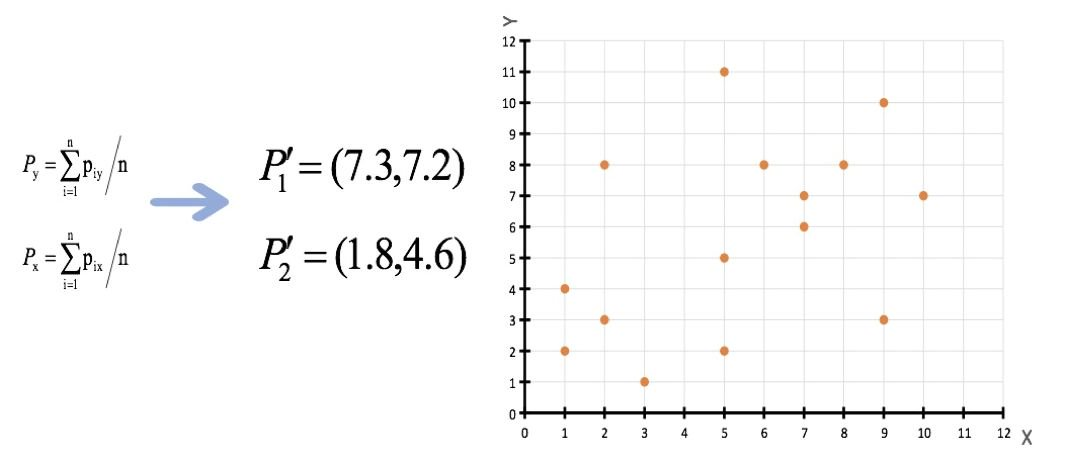

教师文字已经指出图中第二中心需要更正为约 (2.3, 3.3)；本篇使用精确均值计算，迭代时不把中心提前四舍五入。


### 4.1 用 NumPy 核对每一轮

```python
import numpy as np
import pandas as pd

points = np.array([
    [7, 7], [2, 3], [6, 8], [1, 4], [1, 2],
    [3, 1], [8, 8], [9, 10], [10, 7], [5, 5],
    [7, 6], [9, 3], [2, 8], [5, 11], [5, 2],
], dtype=float)
centers = points[[0, 1]].copy()
history = []
for step in range(1, 21):
    d2 = ((points[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
    assigned = d2.argmin(axis=1)  # 并列时选择较小索引
    if any(not np.any(assigned == c) for c in range(2)):
        raise ValueError("出现空簇，需要重新初始化或重新放置中心")
    updated = np.array([points[assigned == c].mean(axis=0) for c in range(2)])
    sse = ((points - updated[assigned]) ** 2).sum()
    history.append({
        "step": step,
        "cluster_1": [f"P{i + 1}" for i in np.flatnonzero(assigned == 0)],
        "cluster_2": [f"P{i + 1}" for i in np.flatnonzero(assigned == 1)],
        "centers": updated.copy(),
        "sse": float(sse),
    })
    if np.allclose(centers, updated, atol=1e-10, rtol=0):
        centers = updated
        break
    centers = updated

for row in history:
    print(row["step"], row["cluster_1"], row["cluster_2"])
    print(np.round(row["centers"], 4), "SSE:", round(row["sse"], 6))
assert np.all(np.diff([row["sse"] for row in history]) <= 1e-10)
```

第二轮只有 $P_{10}$ 从簇 1 移入簇 2，$P_{13}$ 仍在簇 2。最终中心为 $(61/8,60/8)=(7.625,7.5)$ 与 $(19/7,25/7)\approx(2.7143,3.5714)$，SSE 为约 `113.017857`，之后分组不再改变。

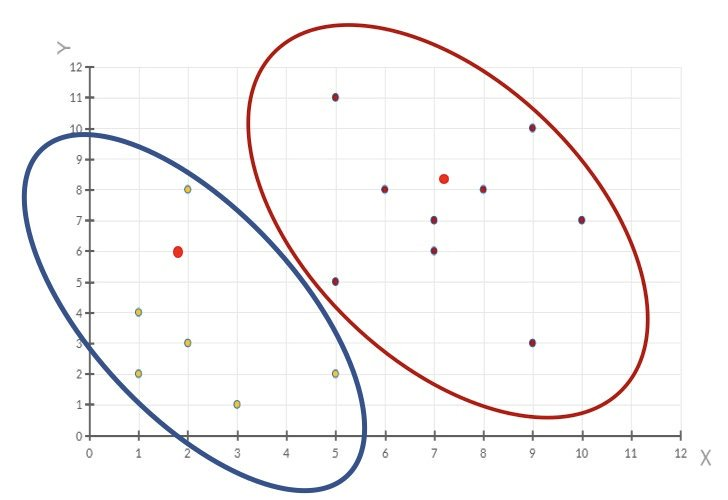

课程手算通过指定初始点来理解流程；API 默认的 `k-means++` 不一定采用这两个点，输出簇编号也可能互换。


## 5. 初始化、重复拟合与复现

| 参数 | 含义 | 使用建议 |
| --- | --- | --- |
| `n_clusters` | 目标簇数 $K$ | 根据候选评估和业务决定 |
| `init="k-means++"` | 优先从离已选中心较远的位置采样中心 | 改善初始化，不保证全局最优 |
| `n_init` | 完整聚类重复运行次数 | 显式设为 20 等整数，最终保留 SSE 最小的运行 |
| `random_state` | 控制初始化随机性 | 固定种子方便复现，再换种子检查稳定性 |
| `max_iter` | 单次拟合的迭代上限 | 常用 300，检查是否触顶 |
| `tol` | 相对收敛容差 | 较小值可能增加计算，不能等同“精度百分比” |

`k-means++` 大致按点到已有最近中心的平方距离进行采样，使初始中心更分散。不同 sklearn 版本的 `n_init` 默认值可能不同，因此本篇统一显式指定。

如果直接传入一个中心数组，通常使用 `n_init=1`，因为多次重复同一组中心并不会引入新的初始化。


### 5.1 完整 API 示例

```python
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X_api, _ = make_blobs(n_samples=150, centers=3, cluster_std=0.6, random_state=22)
model_api = KMeans(
    n_clusters=3, init="k-means++", n_init=20,
    max_iter=300, tol=1e-4, random_state=22,
)
labels_api = model_api.fit_predict(X_api)
X_new_api = X_api[:3] + 0.05
print("labels:", labels_api[:10])
print("centers:", model_api.cluster_centers_)
print("SSE:", model_api.inertia_, "iterations:", model_api.n_iter_)
print("new labels:", model_api.predict(X_new_api))
print("distance to each center:", model_api.transform(X_new_api))

# inertia_ 与手动计算的簇内平方和相同
sse_api = ((X_api - model_api.cluster_centers_[labels_api]) ** 2).sum()
assert np.isclose(sse_api, model_api.inertia_)
```

`fit` 学习中心，`predict` 用既有中心分配新点，`fit_predict` 在拟合后返回训练样本归属，`transform` 返回到各中心的欧氏距离。不要为了给新客户分组再次 `fit_predict`，否则它会重新学习分群规则。

教师笔记中的 `sklearn.datasets.samples_generator.make_blobs` 应改为 `from sklearn.datasets import make_blobs`，`calinski_harabaz_score` 应改为 `calinski_harabasz_score`。


## 6. 特征尺度：为什么收入会压过访问次数

如果收入用元表示、访问次数只有个位数，欧氏距离中收入平方项会支配结果。标准化后，每个数值特征大致均值为 0、标准差为 1，相当于改变了距离中的特征权重。

标准化不是无需判断的固定规则：如果所有维度都有相同单位并希望保留原始几何关系，直接使用原坐标可能更合适。严重长尾可考虑 `log1p`，异常值较多可考虑 `RobustScaler`；这些选择都会改变“相似”的含义。

```python
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

X_scale, _ = make_blobs(n_samples=200, centers=3, random_state=22)
X_scale[:, 0] *= 100
X_train_scale, X_new_scale = train_test_split(X_scale, test_size=0.2, random_state=22)
clusterer = Pipeline([
    ("scale", StandardScaler()),
    ("kmeans", KMeans(n_clusters=3, n_init=20, random_state=22)),
])
labels_train_scale = clusterer.fit_predict(X_train_scale)
labels_new_scale = clusterer.predict(X_new_scale)
print("training cluster counts:", np.bincount(labels_train_scale))
print("new cluster counts:", np.bincount(labels_new_scale, minlength=3))
```

这段演示未来数据的归属：只在训练数据上拟合缩放和中心。若任务是对当前整批客户进行探索，直接拟合当前数据是合理的；若要评估未来表现，就需留出独立时段/数据，并避免用它选择 K。


## 7. 课程二维数据：比较 K=2、3、4

教师示例用 `make_blobs` 生成 1000 个点，中心为 `[-1,-1]、[0,0]、[1,1]、[2,2]`。`cluster_std` 指标准差，不是方差。

```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score

X_blobs, y_blobs_reference = make_blobs(
    n_samples=1000, n_features=2,
    centers=[[-1, -1], [0, 0], [1, 1], [2, 2]],
    cluster_std=[0.4, 0.2, 0.2, 0.2], random_state=9,
)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
blob_records = []
for ax, k in zip(axes, [2, 3, 4]):
    estimator = KMeans(n_clusters=k, n_init=20, random_state=9)
    labels_blobs = estimator.fit_predict(X_blobs)  # 参考标签没有传入
    blob_records.append({
        "K": k, "SSE": estimator.inertia_,
        "SC": silhouette_score(X_blobs, labels_blobs),
        "CH": calinski_harabasz_score(X_blobs, labels_blobs),
    })
    ax.scatter(X_blobs[:, 0], X_blobs[:, 1], c=labels_blobs, s=9, cmap="tab10")
    ax.scatter(*estimator.cluster_centers_.T, c="black", marker="X", s=100)
    ax.set_title(f"K={k}")
    ax.set_xlabel("feature 1")
    ax.set_ylabel("feature 2")
plt.tight_layout()
plt.show()
print(pd.DataFrame(blob_records).round(4))
```

参考标签 `y_blobs_reference` 仅描述生成时的来源，聚类训练不使用它。二维坐标的量纲相同，这里保留原始几何关系；客户收入/消费等异量纲数据则另外处理。

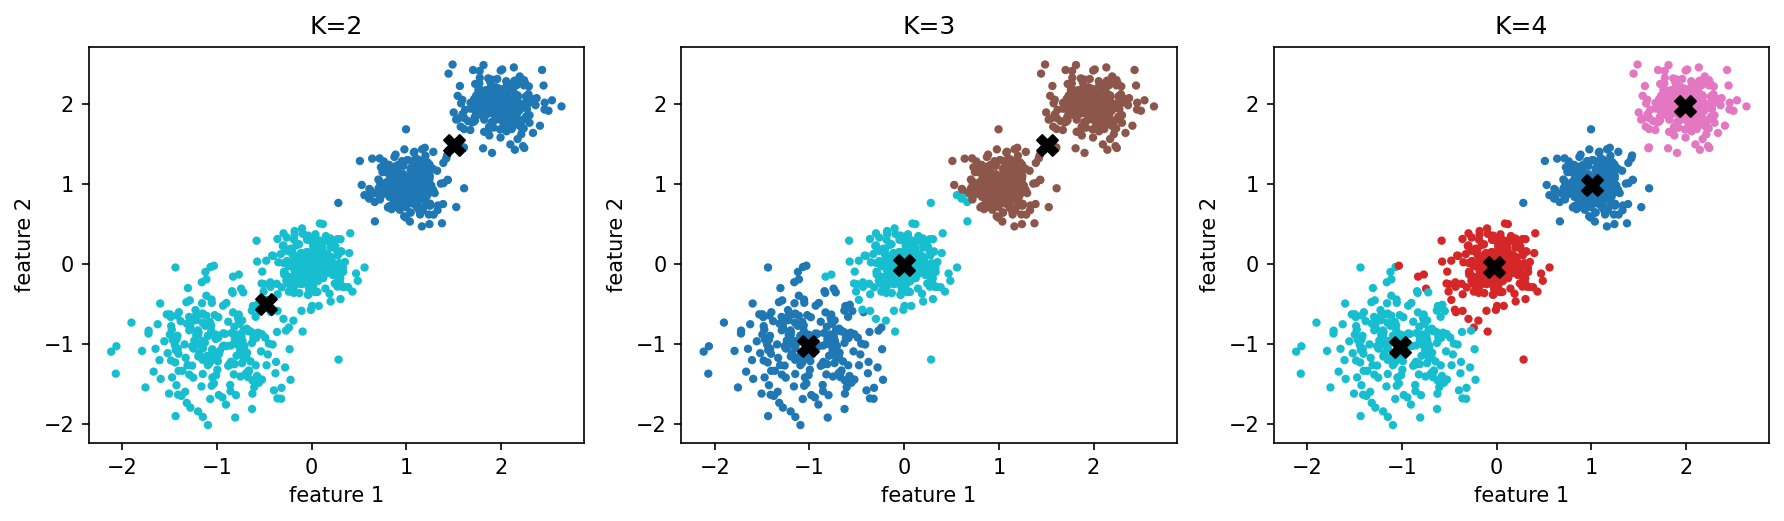

本机离线运行结果（课程生成数据、固定参数）：

| K | SSE | SC | CH |
| --- | ---: | ---: | ---: |
| 2 | 628.3399 | 0.6435 | 3116.1707 |
| 3 | 376.4451 | 0.5763 | 2931.6250 |
| 4 | 137.4625 | 0.6635 | 5924.0506 |


## 8. SSE 与肘部法：降得越来越慢的位置

sklearn 的 `inertia_` 等于拟合数据的簇内平方和。只有在**同一批数据、同一特征表示、同一缩放方式**下，SSE 大小才可直接比较。

全局最优 SSE 随 K 增大不会上升：更多中心至少可以维持原来的分组；K=N 且每个点独立成簇时 SSE=0。但实际 KMeans 找的是局部解，所以不同初始化的实测曲线仍可能出现波动。

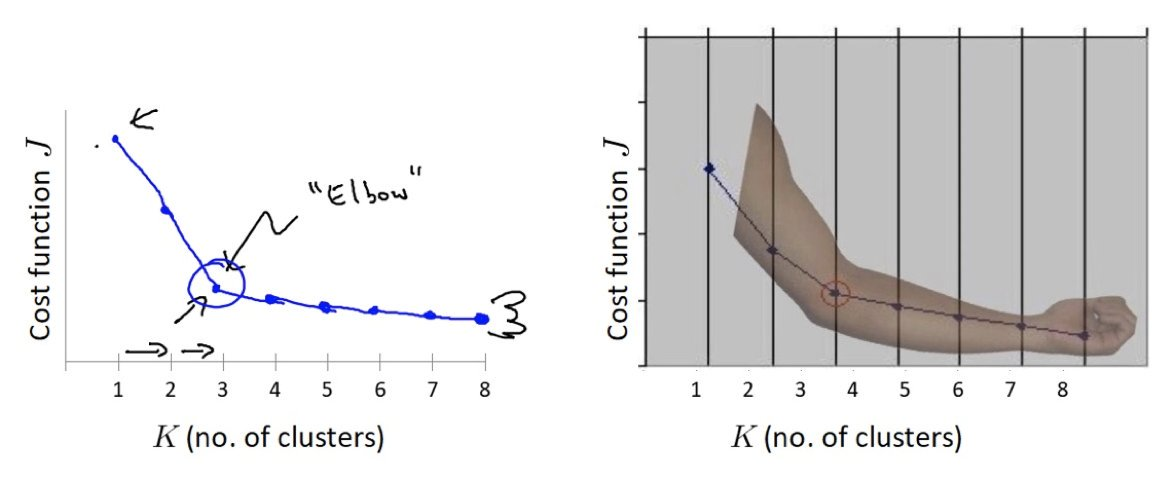

肘部法寻找 SSE 从快速下降转为缓慢下降的转折点。它是候选提示，不是严格证明；不需要为 N 个样本穷举 K=1 到 N，通常按业务规模设定有限候选范围。

`inertia_` 不是测试准确率，不能写成“聚类准确率 95%”。K 越大 SSE 越小也不等于分群越有用。


## 9. 轮廓系数 SC：同时看簇内和簇间

对样本 $i$：

- $a(i)$：它到同簇其他样本的平均距离，不包含它自己；
- $b(i)$：对每个其他簇计算平均距离，再取其中最小值；它不是到最近其他中心的距离。

$$s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))},\qquad SC=\frac1N\sum_{i=1}^{N}s(i)$$

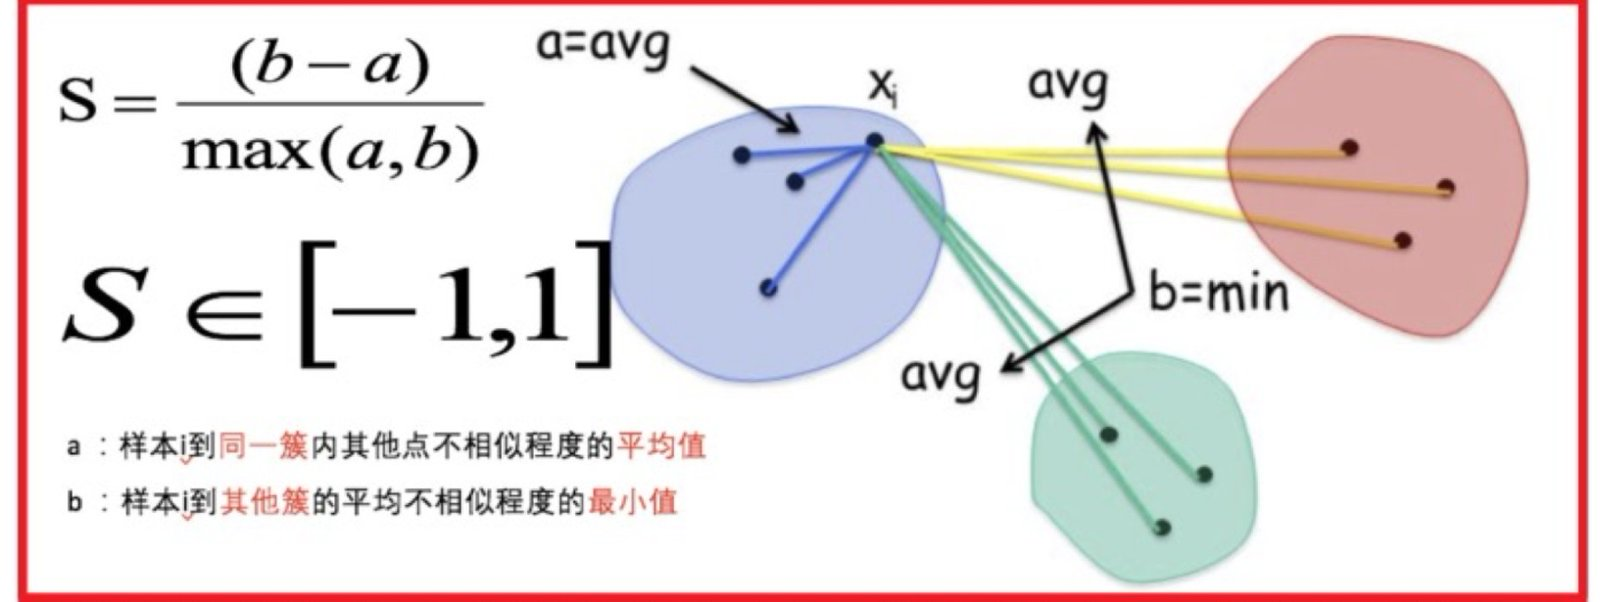

接近 1 表示自身簇内近、其他簇远；接近 0 表示处于簇边界附近；负值提示它可能离其他簇更近。sklearn 对单样本簇的样本轮廓值按 0 处理。

`silhouette_score` 要求实际标签数满足 $2\leq K\leq N-1$；K=1 或每个样本各自成簇时不可计算。距离度量和缩放方式影响结论，非球状簇也可能使这个指标偏好另一种分组。

样本很多时可用 `silhouette_score(X, labels, sample_size=2000, random_state=22)` 近似评估，避免完整样本两两距离的开销；还需保证抽样覆盖足够的簇。


## 10. CH 系数：簇间离散 / 簇内离散

设样本数为 $N$，实际簇数为 $K$，整体均值为 $\bar x$，第 k 簇大小为 $n_k$：

$$SSW=\sum_k\sum_{x_i\in C_k}\lVert x_i-\mu_k\rVert^2$$

$$SSB=\sum_k n_k\lVert\mu_k-\bar x\rVert^2$$

$$CH=\frac{SSB/(K-1)}{SSW/(N-K)}$$

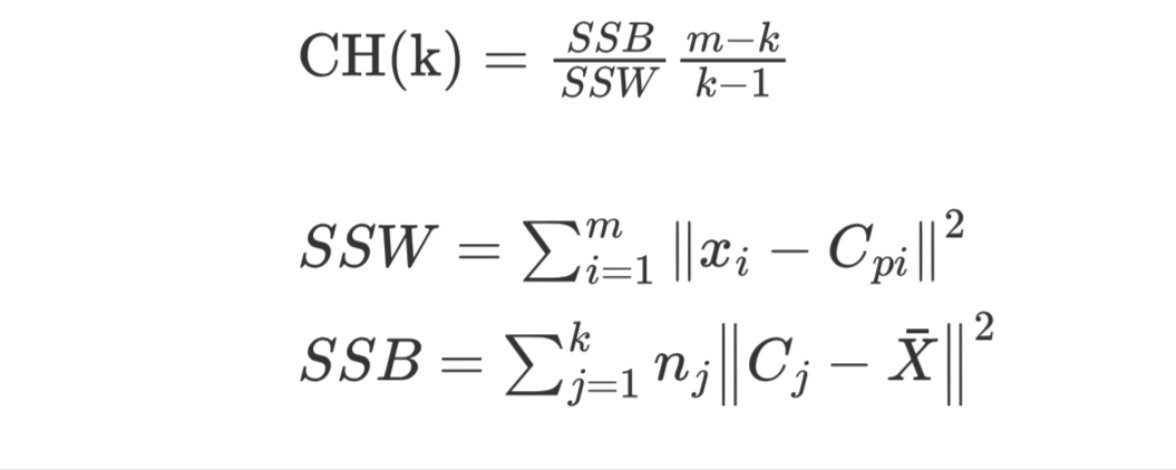

SSW 是簇内**平方**距离之和；SSB 是各簇中心到**全体样本均值**的加权平方距离，不是简单的中心两两距离之和。对普通无样本权重的 KMeans，SSW 与 `inertia_` 相同。

CH 越大通常说明簇内紧凑、簇间分开。公式对簇数做了自由度调整，并不保证总选最少的簇，也不保证最大值就是业务最佳 K。其常规适用范围同样是 $2\leq K\leq N-1$。


### 10.1 手算内部指标，核对 API

```python
import numpy as np
from sklearn.metrics import calinski_harabasz_score, silhouette_samples

X_metric = np.array([[0.], [2.], [8.], [10.]])
labels_metric = np.array([0, 0, 1, 1])
centers_metric = np.array([[1.], [9.]])
ssw = ((X_metric - centers_metric[labels_metric]) ** 2).sum()
ssb = sum(
    (labels_metric == k).sum() * ((centers_metric[k] - X_metric.mean(axis=0)) ** 2).sum()
    for k in range(2)
)
ch_manual = (ssb / (2 - 1)) / (ssw / (len(X_metric) - 2))
sc_manual = np.array([7/9, 5/7, 5/7, 7/9])
assert np.isclose(ssw, 4)
assert np.isclose(ch_manual, 32)
assert np.isclose(ch_manual, calinski_harabasz_score(X_metric, labels_metric))
assert np.allclose(sc_manual, silhouette_samples(X_metric, labels_metric))
print("SSW:", ssw, "SSB:", ssb, "CH:", ch_manual, "SC:", sc_manual.mean())
```

这里第一个点的 $a=2$、$b=(8+10)/2=9$，轮廓值为 $7/9$；第二个点的 $b=(6+8)/2=7$，轮廓值为 $5/7$。整体 SC 约为 `0.746032`。这种小样本核对能帮助避免把 b 算成“到中心的距离”。


## 11. 一次比较多个 K

```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score

X_select, _ = make_blobs(
    n_samples=1000, centers=[[-1,-1], [0,0], [1,1], [2,2]],
    cluster_std=[0.4, 0.2, 0.2, 0.2], random_state=9,
)
k_records = []
for k in range(1, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=9).fit(X_select)
    labels_select = km.labels_
    valid = 2 <= np.unique(labels_select).size < len(X_select)
    k_records.append({
        "K": k, "SSE": km.inertia_,
        "SC": silhouette_score(X_select, labels_select) if valid else np.nan,
        "CH": calinski_harabasz_score(X_select, labels_select) if valid else np.nan,
    })
k_table = pd.DataFrame(k_records)
print(k_table.round(4))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, metric in zip(axes, ["SSE", "SC", "CH"]):
    ax.plot(k_table["K"], k_table[metric], marker="o")
    ax.set_xlabel("K")
    ax.set_title(metric)
plt.tight_layout()
plt.show()
```

K=1 只计算 SSE，SC/CH 保留为 NaN。不同指标可能给出不同建议，需要结合簇大小、画像差异、部署成本与重复拟合的稳定性决定；不要用参考标签逐一试 K 后再宣称无监督发现了类别数。

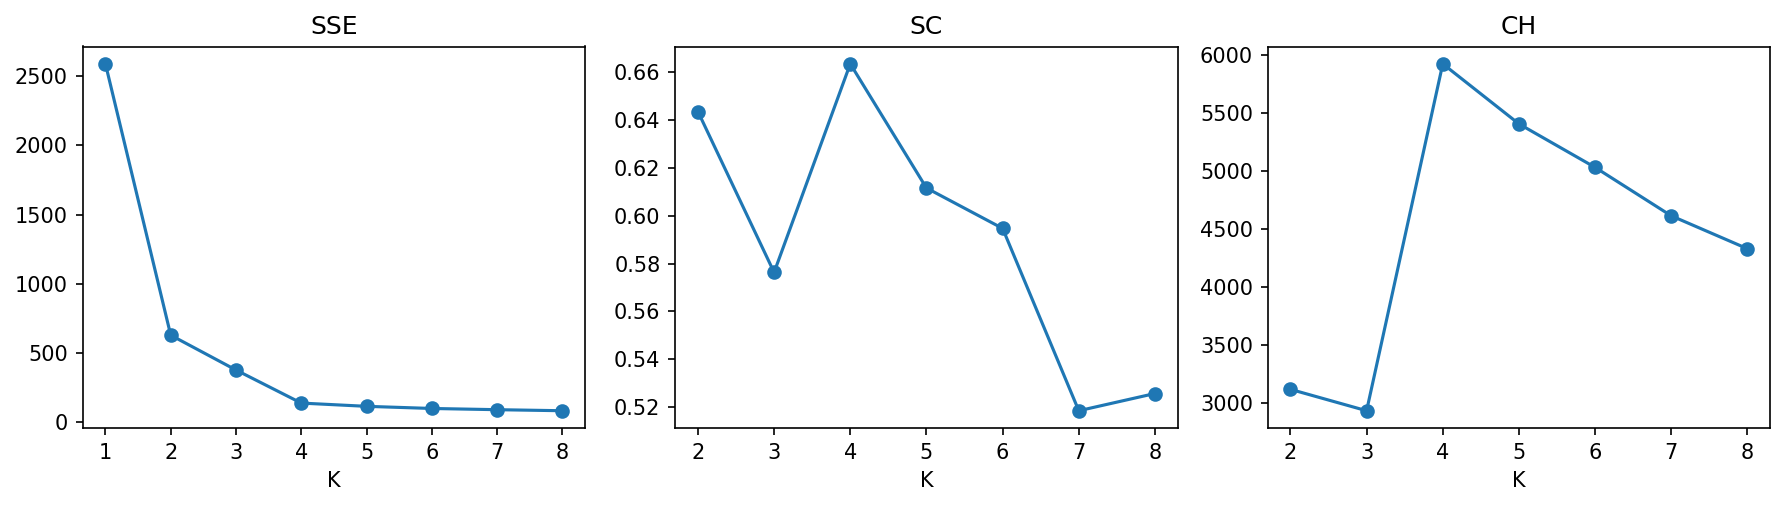


### 11.1 补充曲线图与选择原则

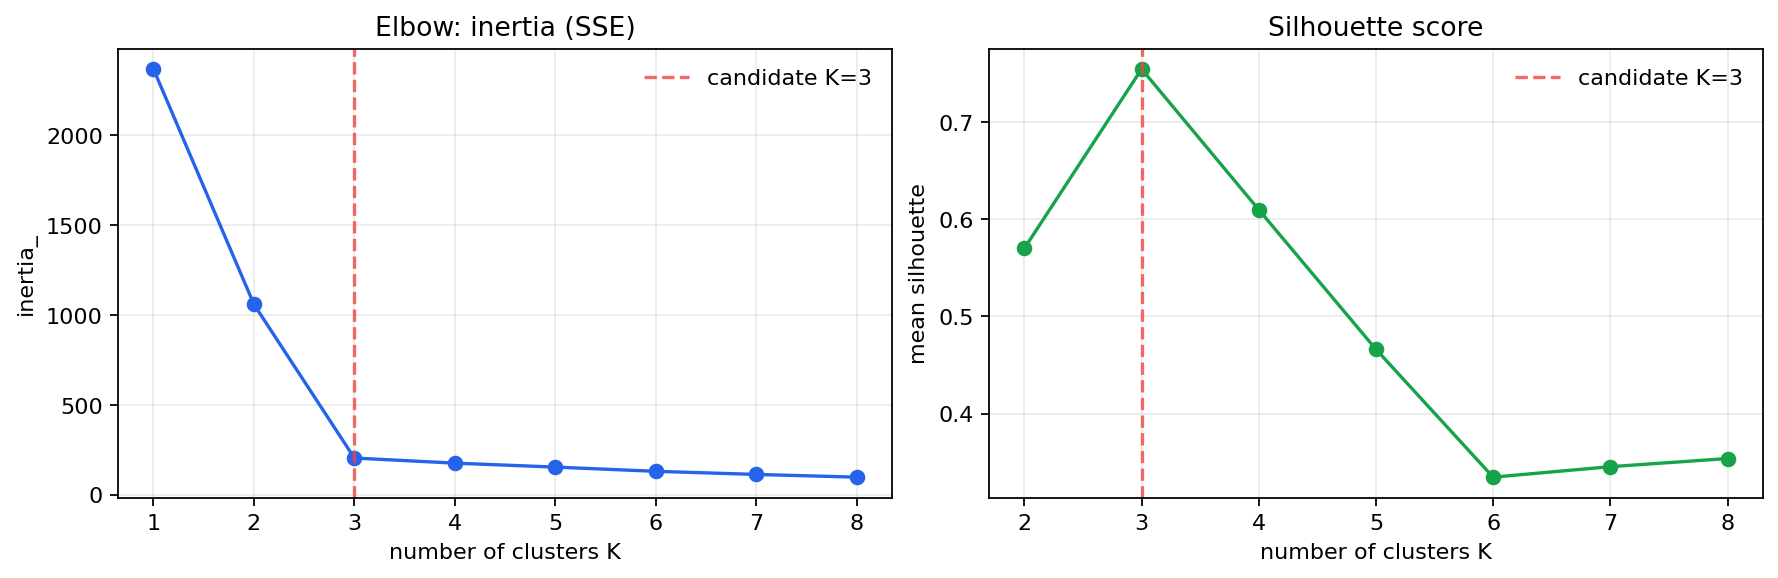

上图来自另一个固定的三簇合成数据，用于展示明显肘部；它与前一节课程四簇数据不是同一次实验。

| 指标 | 希望的方向 | 判断边界 |
| --- | --- | --- |
| SSE / inertia | 同一表示下较小 | K 增大自然下降，不能独立决定 K |
| SC | 通常较大 | 用点到点平均距离，受形状和距离影响 |
| CH | 通常较大 | 基于平方离散程度，偏好紧凑分开的分组 |
| 稳定性 | 重复分组接近 | 稳定分组也可能缺少业务价值 |
| 可解释性 | 特征差异清楚、能行动 | 需要业务画像与后续验证 |


## 12. 课程客户案例：字段和代码问题

课程文件为 `03-代码/customers.csv`，教师描述 200 条客户，字段包括：

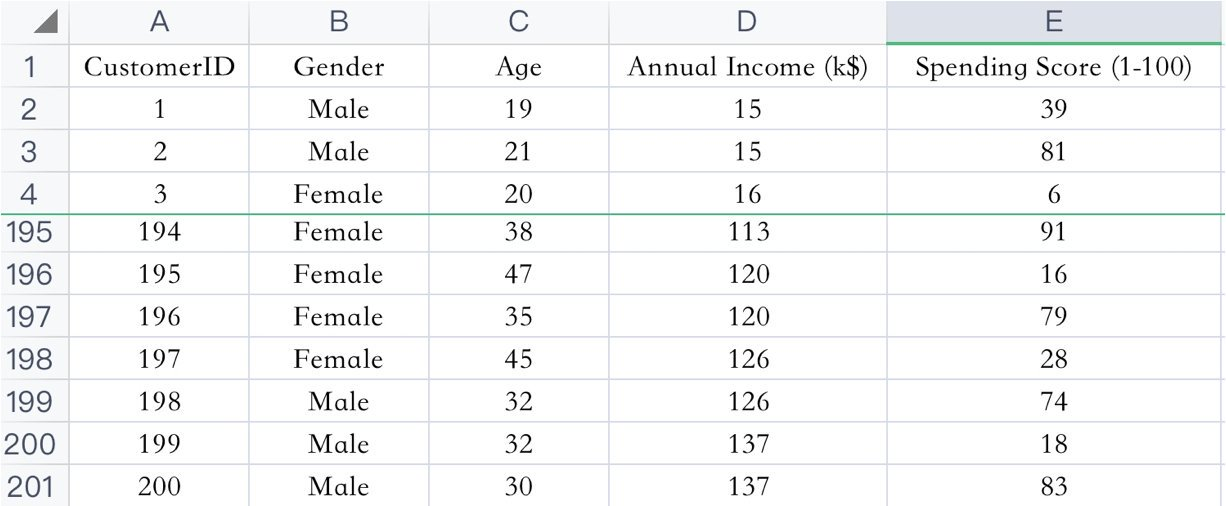

| 字段 | 含义 | 聚类处理 |
| --- | --- | --- |
| CustomerID | 客户标识 | 保留用于关联，排除距离计算 |
| Gender | 性别类别 | 根据业务决定是否需要；需要时使用编码 |
| Age | 年龄 | 数值特征，检查范围与缺失 |
| Annual Income (k$) | 年收入，千美元 | 数值特征，处理量纲 |
| Spending Score (1-100) | 消费指数 | 数值特征，确认它的定义 |

教师示例存在几个需要修正的地方：

- `X`、`y_kmeans`、`mykeans` 与实际变量 `data`、`y_pred`、`estimator` 不一致；
- 结尾字符串使用了弯引号，复制后会产生语法错误；
- 模型设 K=10，绘图却只手写 5 簇，可能遗漏客户；
- 标准化后不能把轴仍直接当作原始收入和消费，也不能把高维中心的前两列随意当作原单位的收入/消费中心；
- 重命名全部列和按位置删 ID 都依赖列顺序，应改为检查并按列名选特征。

本篇先提供收入、消费指数两个数值特征的基础方案，便于解释；再介绍扩展年龄/类别字段的权重问题。K 的取值来自候选分析，不能照抄 10。


### 12.1 可复用的客户分群函数

下面函数接受 DataFrame，检查字段、排除 ID，使用管道拟合缩放器和 KMeans，并输出原单位的簇画像与中心。缺失、负收入和超范围消费指数需要先处理，避免悄悄改变样本含义。

```python
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score

def fit_customer_segments(frame, k, seed=22):
    data = frame.copy()
    data.columns = data.columns.astype(str).str.strip()
    aliases = {"Annual Income (k$)": "Annual Income",
               "Spending Score (1-100)": "Spending Score"}
    data = data.rename(columns=aliases)
    if not data.columns.is_unique:
        raise ValueError("存在重复字段名，请先确认 schema")
    features = ["Annual Income", "Spending Score"]
    missing = set(features) - set(data.columns)
    if missing:
        raise ValueError(f"缺少必要字段：{sorted(missing)}")
    X_customer = data[features].apply(pd.to_numeric, errors="raise")
    if not np.isfinite(X_customer.to_numpy(dtype=float)).all():
        raise ValueError("特征含缺失或非有限值，请先处理")
    if (X_customer["Annual Income"] < 0).any():
        raise ValueError("收入不能为负数")
    if not X_customer["Spending Score"].between(1, 100).all():
        raise ValueError("消费指数必须位于 1 到 100")
    if not 2 <= k < len(data):
        raise ValueError("这里要求 2 <= K < 样本数以计算 SC/CH")
    if len(X_customer.drop_duplicates()) < k:
        raise ValueError("不同特征点少于 K，无法得到要求的簇数")
    if (X_customer.std(ddof=0) == 0).any():
        raise ValueError("存在常数特征，请先重新选择特征")
    pipeline = Pipeline([
        ("scale", StandardScaler()),
        ("kmeans", KMeans(n_clusters=k, n_init=20, random_state=seed)),
    ])
    assigned_customer = pipeline.fit_predict(X_customer)
    if np.unique(assigned_customer).size != k:
        raise ValueError("实际簇数与 K 不一致，请检查数据")
    data["cluster"] = assigned_customer
    profile = data.groupby("cluster").agg(
        customers=("cluster", "size"),
        mean_income=("Annual Income", "mean"),
        mean_spend=("Spending Score", "mean"),
        median_spend=("Spending Score", "median"),
    )
    centers_original = pipeline.named_steps["scale"].inverse_transform(
        pipeline.named_steps["kmeans"].cluster_centers_
    )
    centers_frame = pd.DataFrame(centers_original, columns=features)
    scaled = pipeline.named_steps["scale"].transform(X_customer)
    metrics = {
        "SSE_scaled": pipeline.named_steps["kmeans"].inertia_,
        "SC_scaled": silhouette_score(scaled, assigned_customer),
        "CH_scaled": calinski_harabasz_score(scaled, assigned_customer),
    }
    return pipeline, data, profile, centers_frame, metrics
```

指标是在标准化后的训练数据上计算的，SSE 与原单位数值不可直接比较。全量客户探索没有必须伪造的“测试准确率”；如果要预测未来客户，则在独立未来样本上验证归属、画像与运营效果。


### 12.2 课程 CSV 的使用入口

本次没有成功取得课程 CSV；有文件后使用以下入口。文件缺失时只给出提示，不会偷偷把合成数据当成课程 CSV。

```python
from pathlib import Path
import pandas as pd

course_csv = Path("data/customers.csv")
if course_csv.is_file():
    real_customers = pd.read_csv(course_csv)
    print(real_customers.shape, real_customers.columns.tolist())
    # 先在统一预处理方式下评估候选 K；4 只是演示调用参数
    real_model, real_grouped, real_profile, real_centers, real_metrics = (
        fit_customer_segments(real_customers, k=4)
    )
    print(real_profile.round(2))
    print(real_metrics)
else:
    print("未找到课程 data/customers.csv；请使用下一节的合成数据验证流程。")
```

调用函数依赖上一节。若增加年龄、性别等字段，需要重新评估 K，并说明特征权重；结果不能与只使用收入和消费的分组混称。


## 13. 离线客户分群：合成数据验证完整流程

下面明确生成四种教学人群：低收入低消费、高收入高消费、低收入高消费、高收入低消费。它不代表课程 200 条客户，也没有真正的黄金客户收益标签。

```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng_customer = np.random.default_rng(22)
synthetic_customers = pd.DataFrame({
    "CustomerID": np.arange(1, 281),
    "Annual Income (k$)": np.r_[
        rng_customer.normal(35, 5, 70), rng_customer.normal(80, 8, 70),
        rng_customer.normal(45, 6, 70), rng_customer.normal(90, 7, 70),
    ],
    "Spending Score (1-100)": np.r_[
        rng_customer.normal(28, 6, 70), rng_customer.normal(78, 7, 70),
        rng_customer.normal(75, 6, 70), rng_customer.normal(32, 7, 70),
    ].clip(1, 100),
})
customer_model, grouped, profile, customer_centers, customer_metrics = (
    fit_customer_segments(synthetic_customers, k=4)
)
print(profile.round(2))
print(customer_metrics)

fig, ax = plt.subplots(figsize=(7, 4.5))
for cluster, part in grouped.groupby("cluster"):
    ax.scatter(part["Annual Income"], part["Spending Score"],
               s=22, alpha=0.7, label=f"cluster {cluster}")
ax.scatter(customer_centers["Annual Income"], customer_centers["Spending Score"],
           marker="X", s=160, c="black", label="centers")
ax.set_xlabel("Annual income (k$)")
ax.set_ylabel("Spending score (1-100)")
ax.set_title("Synthetic customer segmentation")
ax.legend(ncol=3)
plt.tight_layout()
plt.show()

# 新客户沿用模型训练时的字段与顺序
new_customers = pd.DataFrame({"Annual Income": [82, 38], "Spending Score": [80, 26]})
print("new customer clusters:", customer_model.predict(new_customers))
```

循环绘图展示所有实际簇，中心经 `inverse_transform` 转回原单位。收入/消费二维图若来自更高维模型，只能视为投影，不能说它完整展示了全部簇结构。

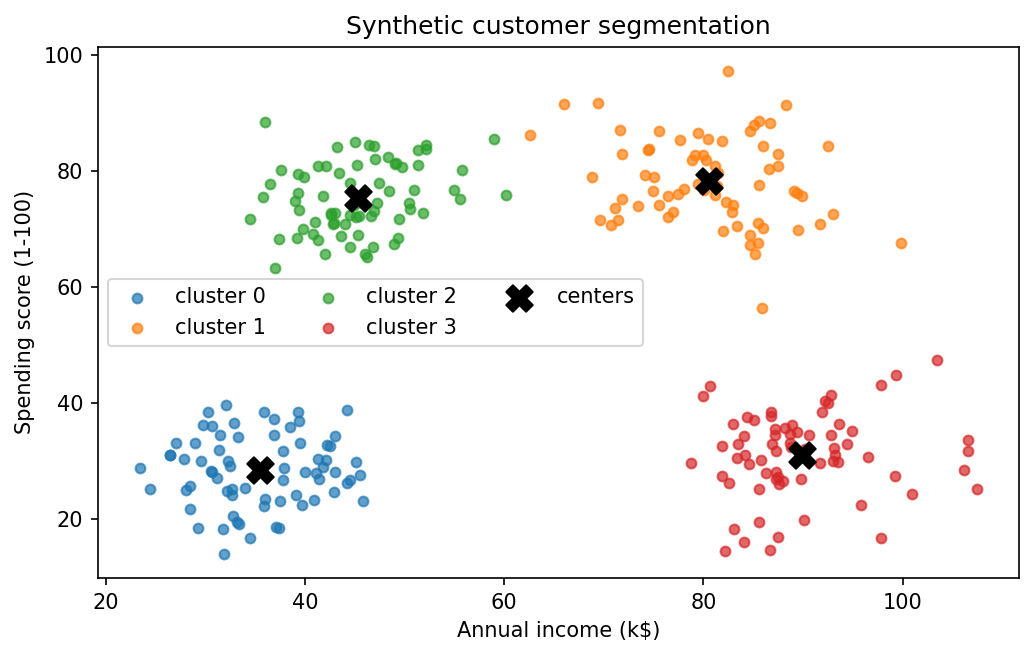

本机合成数据画像（仅教学验证）：

| 簇编号 | 人数 | 平均收入（k$） | 平均消费指数 |
| --- | ---: | ---: | ---: |
| 0 | 70 | 35.42 | 28.32 |
| 1 | 69 | 80.60 | 78.31 |
| 2 | 71 | 45.28 | 75.32 |
| 3 | 70 | 89.93 | 31.05 |

标准化空间训练指标：SSE `39.8713`、SC `0.7134`、CH `1200.1563`。这些指标描述同批合成数据，不能作为真实客户运营效果。


### 13.1 怎样解释客户画像

先查看每簇人数、收入和消费的均值、中位数以及异常点，再命名或制定动作。高收入高消费可作为维护对象，高收入低消费可以探索需求与触达方式；这些是待业务验证的假设，不能由聚类直接证明。

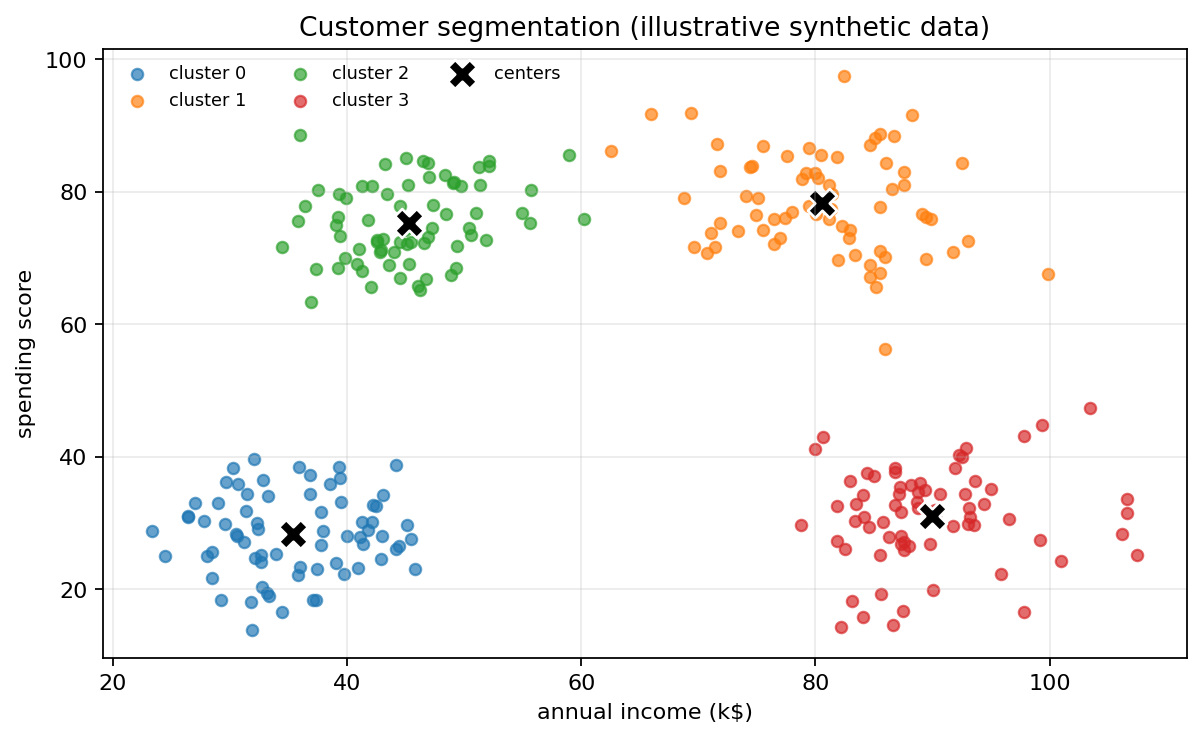

这是使用收入、消费和访问次数三个特征的补充合成数据图；二维轴是收入与消费，黑叉是中心的二维投影。它与上一节仅使用收入/消费两个特征的流程不同，不能混用其指标。

簇编号是任意编号，不表示高低价值；多次训练后簇 0 可能与簇 3 对换。业务命名应基于画像，而非 `0=低、1=中、2=高`。

增加类别变量时可以使用 `ColumnTransformer`：数值列单独标准化，类别列用 `OneHotEncoder(handle_unknown="ignore")`。独热后的多个列会共同改变距离，一组类别列的权重需要解释；不要简单把所有列一起标准化后就认为业务权重自然合理。


## 14. 有参考标签时：ARI / NMI 辅助比较

簇 0 与真实类别 0 没有天然对应关系，不能直接 `accuracy_score(y_true, cluster_ids)`。ARI（调整兰德指数）与 NMI（归一化互信息）对簇编号置换不敏感，适合事后比较分组一致性。

```python
from sklearn.datasets import load_iris
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

iris = load_iris()
iris_clusterer = Pipeline([
    ("scale", StandardScaler()),
    ("kmeans", KMeans(n_clusters=3, n_init=20, random_state=22)),
])
iris_clusters = iris_clusterer.fit_predict(iris.data)
ari_iris = adjusted_rand_score(iris.target, iris_clusters)
nmi_iris = normalized_mutual_info_score(iris.target, iris_clusters)
print("ARI:", ari_iris, "NMI:", nmi_iris)
```

此处 K=3 是按已知 Iris 三种品类演示外部指标；它不是从无标签数据估计类别数的结果。真实标签只用于这一步比较，没有参与 `fit`。不能用同一组参考标签反复调 K 后又把这组 ARI/NMI 称为独立泛化结果。

内部紧凑的簇未必与植物品种完全一致；统计分组和领域标签可能回答不同的问题。

当前离线结果：ARI `0.6201`，NMI `0.6595`，用于复现上述参数，不是分类准确率。


## 15. 稳定性、适用边界和替代方法

不同初始中心可能产生不同结果，可以比较重复运行的 SSE、簇大小以及两次分组的 ARI：

```python
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

X_stable, _ = make_blobs(n_samples=250, centers=4, cluster_std=1.5, random_state=22)
baseline_model = KMeans(n_clusters=4, n_init=20, random_state=22).fit(X_stable)
stability_rows = []
for seed in range(10):
    current = KMeans(n_clusters=4, n_init=20, random_state=seed).fit(X_stable)
    stability_rows.append({
        "seed": seed, "SSE": current.inertia_,
        "ARI_vs_baseline": adjusted_rand_score(baseline_model.labels_, current.labels_),
        "smallest_cluster": int(np.bincount(current.labels_, minlength=4).min()),
    })
print(pd.DataFrame(stability_rows).round(4))
```

这比较的是不同聚类结果的相似性，没有使用真实标签。固定 `random_state` 只保证可复现，不会自动证明结果稳定。进一步可以对抽样扰动、特征变化和时间窗口变化做稳健性检查。

| 限制 | 原因与处理 |
| --- | --- |
| 需要先设 K | 使用多个候选评估，结合业务分组成本 |
| 非凸/长条簇效果可能差 | 平方欧氏距离偏好紧凑团状，考虑 DBSCAN 等 |
| 对异常值敏感 | 均值和平方误差放大异常点影响，检查异常值或考虑更稳健方法 |
| 簇密度/规模差异很大 | 可能把大簇拆开、小簇合并，比较其他模型 |
| 混合类别与数值 | 编码会定义距离权重，必要时使用混合距离或 k-prototypes |
| 超大数据计算成本 | 可考虑 MiniBatchKMeans，评估近似结果与稳定性 |

`MiniBatchKMeans` 用小批量近似更新中心，通常更快，但与完整 KMeans 不保证同一结果。DBSCAN 能识别非凸簇和噪声，但 `eps`、`min_samples` 及尺度同样需要验证。


## 16. 易错点与练习

| 易错说法/做法 | 正确理解 |
| --- | --- |
| K 越大，聚类一定越好 | SSE 自然下降，业务收益不一定增加 |
| KMeans 每次都是全局最优 | 通常只能求到局部解，初始化会影响结果 |
| 轮廓 b 是到另一中心的距离 | 是到其他簇样本的平均距离中的最小值 |
| CH 的 SSW 不用平方 | 它是平方距离之和 |
| 簇 0 就是低价值 | 编号无顺序语义，应基于画像解释 |
| 给新点调用 fit_predict | 会重新拟合，应沿用原管道 predict |
| 所有特征必须标准化 | 缩放是在定义距离权重，应按数据与业务选择 |
| t-SNE 图里分开就代表模型很好 | 降维图会扭曲原空间距离，仅用于辅助展示 |
| K=1 也能算 SC | 至少两个实际簇，且实际簇数小于样本数 |

练习：

1. 重新计算课程 P13 的第一轮距离，并说明 P10 为何第二轮改变归属。
2. 把十五点初始化改为 P4、P12，记录 SSE 序列，并与原初始化比较。
3. 对课程四簇合成数据绘制 K=1 到 8 的 SSE/SC/CH，说明三个指标为何不必完全一致。
4. 把一个特征放大 100 倍，比较缩放前后分组，并解释距离发生了什么变化。
5. 对客户数据分别使用两个、三个特征分群，给每簇写一段含人数、指标、运营假设的画像。
6. 用 `make_moons` 构造月牙簇，比较 KMeans 与 DBSCAN，说明 KMeans 的边界。

参考检查：第一轮 P13 的平方距离为 26、25；第一轮第二中心约 `(2.3333, 3.3333)`；小样本 CH 检查应为 32。


## 17. 来源与验证范围

课程来源：`08_KMeans算法/02-笔记/KMeans聚类算法/聚类.md` 及其 `images` 目录。嵌入 9 张课程配图和 6 张离线实验图；Markdown 预览的相对图片地址失效后，改为读取网盘中的原始图片文件。

课程代码目录中确认存在 `customers.csv`、`day08.zip` 等文件。本次 CSV 下载未成功，本文没有伪造课程 200 条客户的真实分群成绩，也没有执行压缩包或逐段转录视频。十五点手算与教师 `make_blobs` 示例均可由已读取资料复现；完整客户流程在明确标注的合成数据上验证。

本篇检查包含 Notebook 格式、Python 语法和执行、手算结果、sklearn 内部指标、客户流程、新样本预测、全部图片附件与 HTML 显示。前 01—07 篇不做改动。
